# Generere nye tallbilder med en betinget VAE (PyTorch)

I de to første notatbøkene lærte vi en modell å **gjenkjenne** sifre. Nå snur vi problemet: modellen skal **lage** nye bilder av håndskrevne sifre som ikke finnes i datasettet.

Plan:
1. Oppsett
2. Laste MNIST
3. Hva er en VAE?
4. Definere en betinget VAE
5. Trening
6. Generere nye sifre
7. Evaluering med CNN-ene vi allerede har trent
8. Eksport av dekoderen til nettsiden (ONNX)

## 1. Oppsett

In [1]:
import copy
import os

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)

# Bruk Apple-GPU (MPS) hvis tilgjengelig, ellers CPU
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch", torch.__version__, "- enhet:", device)

PyTorch 2.15.0 - enhet: mps


## 2. Laste MNIST

Vi bruker de samme bildene som før, men **uten** `Normalize()`. Generatoren skal lage piksler mellom 0 og 1, og det er enklest når treningsbildene også har verdier mellom 0 og 1.

In [2]:
transform = transforms.ToTensor()   # verdier 0–1, form [1, 28, 28]

train_data = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_data = datasets.MNIST(root="data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=1000)

print(len(train_data), "treningsbilder,", len(test_data), "testbilder")

60000 treningsbilder, 10000 testbilder


## 3. Hva er en VAE?

En **variational autoencoder (VAE)** består av to nettverk:

- **Koderen** ser på et bilde og presser det sammen til noen få tall, her 8. Disse tallene kalles det **latente rommet**. De beskriver *hvordan* sifferet er skrevet: tykkelse, helning, bredde, om 7-tallet har tverrstrek, og så videre.
- **Dekoderen** gjør det motsatte: den får de 8 tallene og tegner et 28×28-bilde ut fra dem.

Under treningen sendes bildet gjennom begge, og modellen lærer å gjenskape bildet den fikk inn. Når treningen er ferdig, kaster vi koderen og beholder bare dekoderen. Da kan vi trekke 8 tilfeldige tall og få et helt nytt siffer.

### Hvorfor «variational»?
En vanlig autoencoder kan plassere bildene hvor som helst i det latente rommet, med store hull mellom dem. Trekker man tilfeldige tall, havner man ofte i et hull, og dekoderen tegner noe meningsløst.

En VAE løser dette ved at koderen ikke gir ett punkt, men en **fordeling**: et gjennomsnitt `mu` og en spredning `sigma` for hvert av de 8 tallene. Under treningen trekkes et tilfeldig punkt fra denne fordelingen. Tapsfunksjonen har to deler:

1. **Rekonstruksjonstap** (binær cross-entropy): Hvor likt er det gjenskapte bildet originalen?
2. **KL-divergens**: Hvor langt er fordelingen fra en standard normalfordeling (gjennomsnitt 0, standardavvik 1)?

Den andre delen tvinger alle bildene inn i det samme, tette området rundt null. Da kan vi senere trekke tall fra en standard normalfordeling og vite at dekoderen har sett noe lignende før.

### Hvorfor «betinget»?
I en **betinget VAE** (cVAE) får både koderen og dekoderen også vite hvilket siffer det er, som en *one-hot-vektor* (for eksempel `[0,0,0,1,0,0,0,0,0,0]` for 3). Da trenger ikke det latente rommet å huske *hvilket* siffer det er, bare *stilen*. Fordelen er at vi selv kan velge hvilket siffer vi vil generere, og at samme stil kan brukes på alle ti sifrene.

## 4. Definere en betinget VAE

- **Koderen** bruker konvolusjoner med `stride=2`, som halverer bildestørrelsen, i stedet for pooling: 28 → 14 → 7.
- **Dekoderen** bruker **transponerte konvolusjoner** (`ConvTranspose2d`), som gjør det motsatte og dobler størrelsen: 7 → 14 → 28.
- Det siste laget gir *logits*. `sigmoid` gjør dem om til pikselverdier mellom 0 og 1.

In [3]:
LATENT = 8        # antall tall i det latente rommet
KLASSER = 10


class CVAE(nn.Module):
    def __init__(self, latent=LATENT):
        super().__init__()
        # Koder: bilde → egenskaper
        self.enc_conv = nn.Sequential(
            nn.Conv2d(1, 32, 4, stride=2, padding=1), nn.ReLU(),    # 32 × 14 × 14
            nn.Conv2d(32, 64, 4, stride=2, padding=1), nn.ReLU(),   # 64 × 7 × 7
            nn.Flatten(),                                           # 3136
        )
        self.enc_fc = nn.Sequential(nn.Linear(64 * 7 * 7 + KLASSER, 256), nn.ReLU())
        self.mu = nn.Linear(256, latent)
        self.logvar = nn.Linear(256, latent)   # log(sigma²): kan være negativ, mer stabilt enn sigma

        # Dekoder: latente tall + siffer → bilde
        self.dec_fc = nn.Sequential(
            nn.Linear(latent + KLASSER, 256), nn.ReLU(),
            nn.Linear(256, 64 * 7 * 7), nn.ReLU(),
        )
        self.dec_conv = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1), nn.ReLU(),   # 32 × 14 × 14
            nn.ConvTranspose2d(32, 1, 4, stride=2, padding=1),               # 1 × 28 × 28 (logits)
        )

    def encode(self, x, y):
        h = self.enc_fc(torch.cat([self.enc_conv(x), y], dim=1))
        return self.mu(h), self.logvar(h)

    def decode(self, z, y):
        h = self.dec_fc(torch.cat([z, y], dim=1))
        return self.dec_conv(h.view(-1, 64, 7, 7))

    def forward(self, x, y):
        mu, logvar = self.encode(x, y)
        # «Reparametrisering»: trekk z = mu + sigma · støy, slik at gradientene kan gå gjennom mu og sigma
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return self.decode(z, y), mu, logvar


def one_hot(labels):
    return F.one_hot(labels, KLASSER).float()


def vae_loss(logits, x, mu, logvar):
    # Summer over pikslene, snitt over bildene i batchen
    rekonstruksjon = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / len(x)
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / len(x)
    return rekonstruksjon, kl


vae = CVAE().to(device)
print(f"{sum(p.numel() for p in vae.parameters()):,} vekter".replace(",", " "))

1 687 249 vekter


## 5. Trening

Tapet er summen av rekonstruksjonstap og KL-divergens per bilde. Vi skriver ut begge delene, slik at vi ser hvordan de utvikler seg. Rekonstruksjonstapet bør synke jevnt, mens KL-tapet først stiger litt fordi modellen begynner å bruke det latente rommet.

In [4]:
optimizer = optim.Adam(vae.parameters(), lr=1e-3)
EPOKER = 30


def evaluate():
    vae.eval()
    rek_sum = kl_sum = 0.0
    with torch.no_grad():
        for x, labels in test_loader:
            x, y = x.to(device), one_hot(labels).to(device)
            logits, mu, logvar = vae(x, y)
            rek, kl = vae_loss(logits, x, mu, logvar)
            rek_sum += rek.item() * len(x)
            kl_sum += kl.item() * len(x)
    n = len(test_loader.dataset)
    return rek_sum / n, kl_sum / n


for epoch in range(1, EPOKER + 1):
    vae.train()
    for x, labels in train_loader:
        x, y = x.to(device), one_hot(labels).to(device)
        optimizer.zero_grad()
        logits, mu, logvar = vae(x, y)
        rek, kl = vae_loss(logits, x, mu, logvar)
        (rek + kl).backward()
        optimizer.step()

    rek, kl = evaluate()
    print(f"Epoke {epoch:2d}: rekonstruksjon {rek:6.1f}   KL {kl:5.1f}   totalt {rek + kl:6.1f}")

Epoke  1: rekonstruksjon  126.1   KL   8.1   totalt  134.2


Epoke  2: rekonstruksjon  101.7   KL  12.2   totalt  113.9


Epoke  3: rekonstruksjon   96.0   KL  13.3   totalt  109.3


Epoke  4: rekonstruksjon   93.7   KL  13.1   totalt  106.8


Epoke  5: rekonstruksjon   92.5   KL  13.0   totalt  105.6


Epoke  6: rekonstruksjon   91.0   KL  13.5   totalt  104.4


... (20 outputs left out)

Epoke 27: rekonstruksjon   86.8   KL  13.5   totalt  100.3


Epoke 28: rekonstruksjon   86.9   KL  13.2   totalt  100.1


Epoke 29: rekonstruksjon   86.8   KL  13.1   totalt  100.0


Epoke 30: rekonstruksjon   87.0   KL  12.9   totalt   99.9


In [5]:
torch.save(vae.state_dict(), "cvae.pt")

### Rekonstruksjon
Øverste rad viser originale testbilder, nederste rad viser hva VAE-en gjenskaper etter å ha presset dem gjennom 8 tall. Gjenskapingen er litt uskarp. Det er typisk for en VAE.

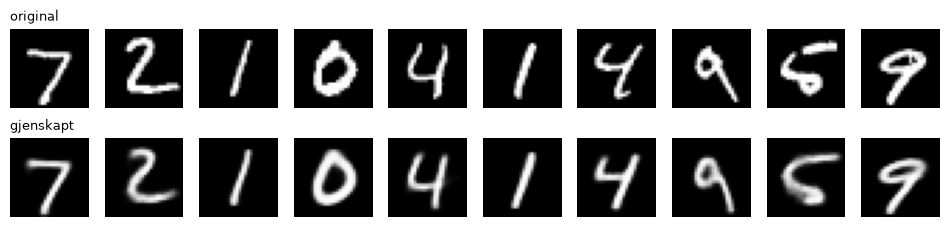

In [6]:
vae.eval()
x, labels = next(iter(test_loader))
with torch.no_grad():
    logits, _, _ = vae(x[:10].to(device), one_hot(labels[:10]).to(device))
    rekonstruert = torch.sigmoid(logits).cpu()

fig, axes = plt.subplots(2, 10, figsize=(12, 2.6))
for i in range(10):
    axes[0, i].imshow(x[i].squeeze(), cmap="gray")
    axes[1, i].imshow(rekonstruert[i].squeeze(), cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].axis("off")
axes[0, 0].set_title("original", loc="left", fontsize=9)
axes[1, 0].set_title("gjenskapt", loc="left", fontsize=9)
plt.show()

## 6. Generere nye sifre

Nå bruker vi bare dekoderen. Vi trekker tilfeldige tall fra en standard normalfordeling og velger hvilket siffer vi vil ha.

I rutenettet under har hver **kolonne** sine egne tilfeldige latente tall, altså én stil, og hver **rad** er et siffer. Legg merke til at stilen, for eksempel tykkelse og helning, følger med nedover kolonnen, selv om sifferet endres.

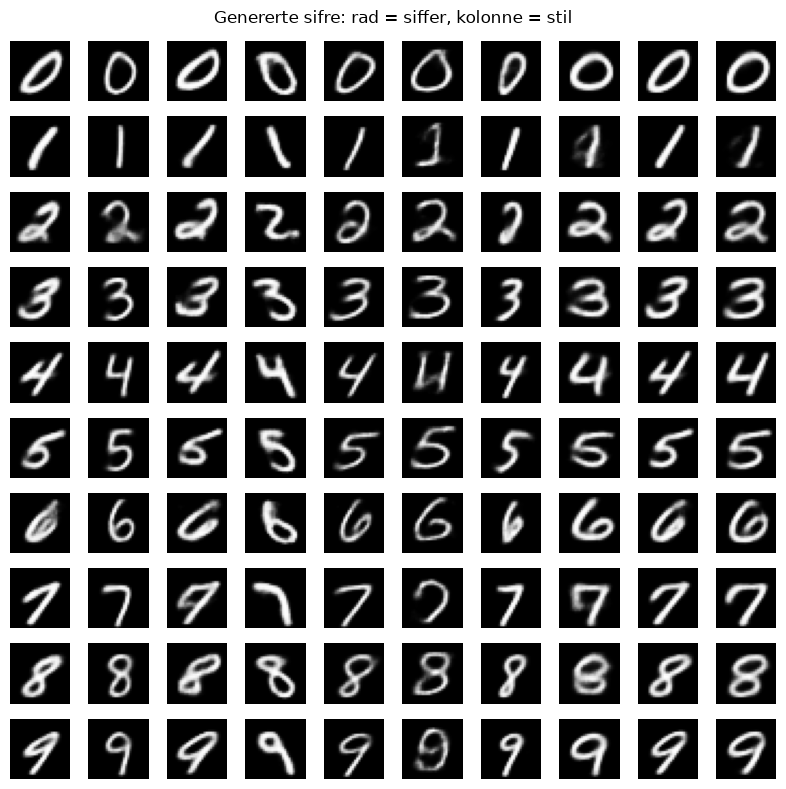

In [7]:
@torch.no_grad()
def generate(digits, z=None):
    # Lag bilder av de gitte sifrene. z = latente tall (trekkes tilfeldig hvis ikke gitt).
    digits = torch.as_tensor(digits)
    if z is None:
        z = torch.randn(len(digits), LATENT)
    vae.eval()
    return torch.sigmoid(vae.decode(z.to(device), one_hot(digits).to(device))).cpu()


stiler = torch.randn(10, LATENT)          # 10 stiler, én per kolonne
fig, axes = plt.subplots(10, 10, figsize=(8, 8))
for digit in range(10):
    bilder = generate([digit] * 10, stiler)
    for col in range(10):
        axes[digit, col].imshow(bilder[col].squeeze(), cmap="gray")
        axes[digit, col].axis("off")
plt.suptitle("Genererte sifre: rad = siffer, kolonne = stil")
plt.tight_layout()
plt.show()

### Interpolasjon mellom to stiler
Siden det latente rommet er tett og sammenhengende, kan vi gå gradvis fra én stil til en annen. Hvert steg er et nytt bilde som modellen aldri har sett.

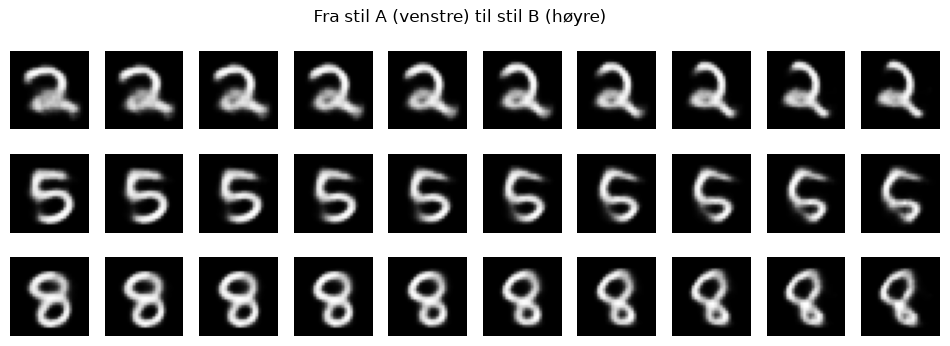

In [8]:
a, b = torch.randn(LATENT), torch.randn(LATENT)
steg = torch.linspace(0, 1, 10)
z = torch.stack([(1 - t) * a + t * b for t in steg])

fig, axes = plt.subplots(3, 10, figsize=(12, 3.8))
for row, digit in enumerate([2, 5, 8]):
    bilder = generate([digit] * 10, z)
    for col in range(10):
        axes[row, col].imshow(bilder[col].squeeze(), cmap="gray")
        axes[row, col].axis("off")
plt.suptitle("Fra stil A (venstre) til stil B (høyre)")
plt.show()

### Hva betyr de latente tallene?
Vi holder alle tallene på 0 og endrer ett av dem om gangen fra −3 til 3. Noen av tallene får en tydelig betydning, for eksempel helning eller strektykkelse. Andre gjør lite. Modellen har selv funnet ut hva den vil bruke dem til.

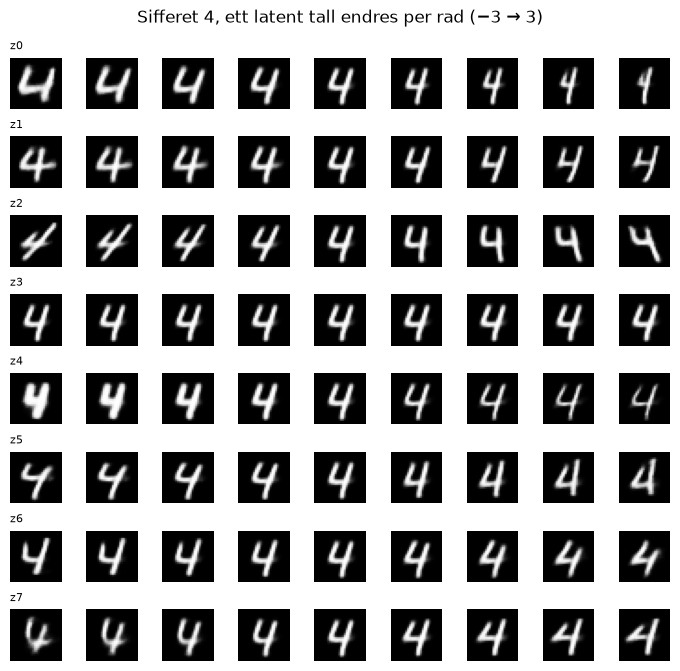

In [9]:
verdier = torch.linspace(-3, 3, 9)
fig, axes = plt.subplots(LATENT, 9, figsize=(7, 0.85 * LATENT))
for dim in range(LATENT):
    z = torch.zeros(9, LATENT)
    z[:, dim] = verdier
    bilder = generate([4] * 9, z)
    for col in range(9):
        axes[dim, col].imshow(bilder[col].squeeze(), cmap="gray")
        axes[dim, col].axis("off")
    axes[dim, 0].set_title(f"z{dim}", loc="left", fontsize=8)
plt.suptitle("Sifferet 4, ett latent tall endres per rad (−3 → 3)")
plt.tight_layout()
plt.show()

## 7. Evaluering med CNN-ene vi allerede har trent

Det er vanskelig å si med tall hvor «gode» genererte bilder er. Et praktisk mål er å la klassifisereren fra `01_mnist_cnn.ipynb` se på dem: Hvis vi ber om et 7-tall og CNN-et er sikkert på at det er et 7-tall, er bildet sannsynligvis lesbart.

Vi lager 1000 bilder av hvert siffer og måler:
- hvor stor andel CNN-et gjenkjenner som riktig siffer
- hvor stor andel modellen med «ikke tall» fra `02_ikke_tall.ipynb` mener ikke er et tall

CNN-ene ble trent på normaliserte bilder, så vi normaliserer de genererte bildene på samme måte før vi sender dem inn.

In [10]:
class CNN(nn.Module):
    # Samme arkitektur som i 01 og 02
    def __init__(self, antall_klasser=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, antall_klasser),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


cnn = CNN(10)
cnn.load_state_dict(torch.load("mnist_cnn.pt", map_location="cpu"))
cnn_nan = CNN(11)
cnn_nan.load_state_dict(torch.load("mnist_cnn_ikke_tall.pt", map_location="cpu"))
cnn, cnn_nan = cnn.to(device).eval(), cnn_nan.to(device).eval()


@torch.no_grad()
def evaluer(etterbehandling=lambda b: b, per_siffer=1000):
    torch.manual_seed(0)
    riktig_totalt = ikke_tall_totalt = 0
    for digit in range(10):
        bilder = etterbehandling(generate([digit] * per_siffer)).to(device)
        normalisert = (bilder - 0.1307) / 0.3081
        riktig = (cnn(normalisert).argmax(1) == digit).sum().item()
        ikke_tall = (cnn_nan(normalisert).argmax(1) == 10).sum().item()
        riktig_totalt += riktig
        ikke_tall_totalt += ikke_tall
        print(f"Siffer {digit}: {100 * riktig / per_siffer:5.1f} % gjenkjent riktig,"
              f" {100 * ikke_tall / per_siffer:5.1f} % «ikke tall»")
    n = 10 * per_siffer
    print(f"\nTotalt: {100 * riktig_totalt / n:.1f} % gjenkjent riktig,"
          f" {100 * ikke_tall_totalt / n:.1f} % «ikke tall»")


evaluer()

Siffer 0:  98.1 % gjenkjent riktig,  99.1 % «ikke tall»
Siffer 1:  92.6 % gjenkjent riktig,  54.1 % «ikke tall»
Siffer 2:  98.2 % gjenkjent riktig,  99.9 % «ikke tall»


Siffer 3:  97.5 % gjenkjent riktig, 100.0 % «ikke tall»
Siffer 4:  99.4 % gjenkjent riktig,  99.6 % «ikke tall»
Siffer 5:  96.7 % gjenkjent riktig, 100.0 % «ikke tall»


Siffer 6:  95.4 % gjenkjent riktig,  98.8 % «ikke tall»
Siffer 7:  94.5 % gjenkjent riktig,  91.4 % «ikke tall»
Siffer 8:  99.4 % gjenkjent riktig, 100.0 % «ikke tall»


Siffer 9:  96.8 % gjenkjent riktig, 100.0 % «ikke tall»

Totalt: 96.9 % gjenkjent riktig, 94.3 % «ikke tall»


### Et overraskende funn: modellen med «ikke tall» liker ikke uskarpe streker
CNN-et fra 01 gjenkjenner de aller fleste genererte sifrene, men modellen fra 02 mener at de fleste *ikke* er tall. Bildene ser jo ut som sifre, så hva skjer?

Forskjellen er at VAE-bildene er litt **uskarpe**. Ekte MNIST-sifre har en hvit kjerne og skarpe kanter, mens VAE-en tegner mykere overganger. Vi kan teste om det er årsaken: Ta ekte MNIST-testbilder, gjør dem litt uskarpe med et 3×3-gjennomsnittsfilter, og se hva modellen fra 02 sier.

In [11]:
ekte = torch.stack([test_data[i][0] for i in range(2000)])
uskarp = F.avg_pool2d(F.pad(ekte, (1, 1, 1, 1)), 3, stride=1)   # gjennomsnitt av hver 3×3-rute

with torch.no_grad():
    for navn, bilder in [("ekte MNIST", ekte), ("uskarp MNIST", uskarp)]:
        andel = (cnn_nan(((bilder - 0.1307) / 0.3081).to(device)).argmax(1) == 10).float().mean()
        print(f"{navn:13s}: {100 * andel:5.1f} % «ikke tall»")

ekte MNIST   :   1.0 % «ikke tall»


uskarp MNIST : 100.0 % «ikke tall»


Nesten alle de uskarpe, ekte sifrene blir kalt «ikke tall». Modellen fra 02 har altså lært en **snarvei**: uskarpe streker betyr «ikke tall». Det er sannsynligvis fordi EMNIST-bokstavene den så som «ikke tall», er mer uskarpe enn MNIST-sifrene. Dette er et klassisk problem i maskinlæring: modellen lærer det som *skiller* kategoriene i treningsdataene, ikke nødvendigvis det vi mente den skulle lære.

To mulige løsninger:
1. Tren modellen i 02 på nytt med uskarpe sifre blant treningsdataene, slik at uskarphet ikke lenger skiller kategoriene.
2. Gjør de genererte bildene skarpere, slik at de ligner mer på MNIST.

Her gjør vi det siste: Vi øker kontrasten, slik at piksler under 0,2 blir svarte, piksler over 0,7 blir hvite, og det som er imellom strekkes ut. Det er samme triks som ble brukt på EMNIST-bokstavene i 02.

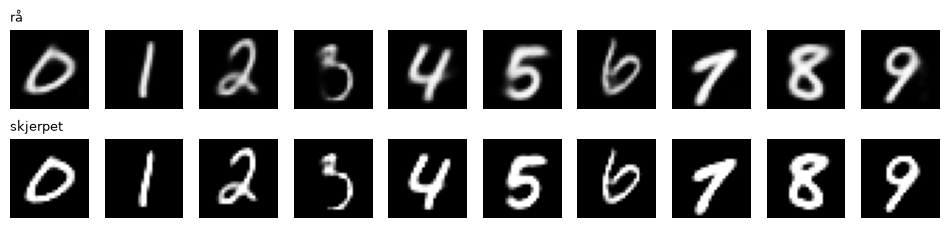

Siffer 0:  97.8 % gjenkjent riktig,   2.2 % «ikke tall»


Siffer 1:  94.5 % gjenkjent riktig,   4.9 % «ikke tall»
Siffer 2:  98.8 % gjenkjent riktig,  11.0 % «ikke tall»


Siffer 3:  99.4 % gjenkjent riktig,   1.4 % «ikke tall»


Siffer 4:  99.1 % gjenkjent riktig,   3.6 % «ikke tall»
Siffer 5:  98.1 % gjenkjent riktig,   2.5 % «ikke tall»


Siffer 6:  96.5 % gjenkjent riktig,   2.6 % «ikke tall»


Siffer 7:  97.2 % gjenkjent riktig,   3.2 % «ikke tall»
Siffer 8:  98.2 % gjenkjent riktig,   6.7 % «ikke tall»


Siffer 9:  96.7 % gjenkjent riktig,   4.0 % «ikke tall»

Totalt: 97.6 % gjenkjent riktig, 4.2 % «ikke tall»


In [12]:
def skjerp(bilder, lav=0.2, høy=0.7):
    return ((bilder - lav) / (høy - lav)).clamp(0, 1)


torch.manual_seed(3)
bilder = generate(list(range(10)))
fig, axes = plt.subplots(2, 10, figsize=(12, 2.6))
for i in range(10):
    axes[0, i].imshow(bilder[i].squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[1, i].imshow(skjerp(bilder[i]).squeeze(), cmap="gray", vmin=0, vmax=1)
    axes[0, i].axis("off")
    axes[1, i].axis("off")
axes[0, 0].set_title("rå", loc="left", fontsize=9)
axes[1, 0].set_title("skjerpet", loc="left", fontsize=9)
plt.show()

evaluer(skjerp)

### Hvilke bilder feiler?
Bildene under ble generert som ett siffer, men CNN-et mente det var et annet. Ofte er de genererte bildene virkelig tvetydige, og noen ganger ville et menneske også nølt.

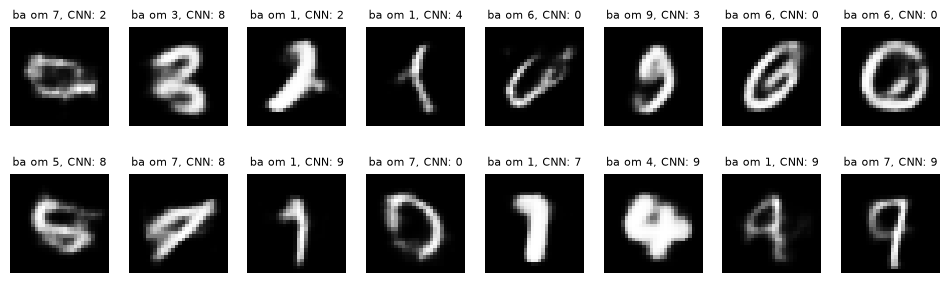

69 av 2000 ble feilklassifisert


In [13]:
torch.manual_seed(1)
digits = torch.arange(10).repeat(200)
with torch.no_grad():
    bilder = generate(digits)
    gjett = cnn(((bilder - 0.1307) / 0.3081).to(device)).argmax(1).cpu()
feil = (gjett != digits).nonzero().squeeze(1)

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, feil[:16]):
    ax.imshow(bilder[i].squeeze(), cmap="gray")
    ax.set_title(f"ba om {digits[i]}, CNN: {gjett[i]}", fontsize=8)
plt.show()
print(len(feil), "av", len(digits), "ble feilklassifisert")

## 8. Eksport til nettsiden (ONNX)

Nettsiden trenger bare **dekoderen**. Den får inn de 8 latente tallene og en one-hot-vektor for sifferet, og gir tilbake et 28×28-bilde med verdier 0–1. `sigmoid` og skjerpingen er bygget inn i modellen, akkurat som softmax var det i klassifisererne.

In [14]:
class GeneratorForWeb(nn.Module):
    # Dekoderen + sigmoid + skjerping, klar for nettleseren.
    def __init__(self, vae):
        super().__init__()
        self.vae = vae

    def forward(self, z, digit):          # z: [1, 8], digit: [1, 10] one-hot
        return skjerp(torch.sigmoid(self.vae.decode(z, digit)))


web_model = GeneratorForWeb(copy.deepcopy(vae).cpu()).eval()

os.makedirs("docs", exist_ok=True)
torch.onnx.export(
    web_model,
    (torch.randn(1, LATENT), one_hot(torch.tensor([3]))),
    "docs/generator.onnx",
    input_names=["z", "digit"],
    output_names=["image"],
    external_data=False,                  # alle vektene i én fil
)
print("Lagret docs/generator.onnx,", os.path.getsize("docs/generator.onnx") // 1024, "kB")

[torch.onnx] Obtain model graph for `GeneratorForWeb([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `GeneratorForWeb([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Lagret docs/generator.onnx, 3313 kB


### Kontroll: gir ONNX-modellen samme bilde som PyTorch?

In [15]:
import onnxruntime as ort

session = ort.InferenceSession("docs/generator.onnx")
z = torch.randn(1, LATENT)
y = one_hot(torch.tensor([7]))
onnx_bilde = session.run(None, {"z": z.numpy(), "digit": y.numpy()})[0]
torch_bilde = web_model(z, y).detach().numpy()
print("Største forskjell:", abs(onnx_bilde - torch_bilde).max())

Største forskjell: 4.172325e-07
